In [ ]:
import sys
sys.path.insert(0, 'baseframework')
sys.path.insert(0, 'baseframework/data')
import numpy as np
import matplotlib.pyplot as plt
from baseframework import datahandler
from baseframework.offline_clustering.adjacency import adjacency_clustering
from baseframework.offline_clustering.density_peak_clustering import DensityPeakClustering

# Dataset Visualization

In [ ]:
from baseframework import datahandler
import numpy as np
import matplotlib.pyplot as plt

# ── Config ───────────────────────────────────────────────────────────────────────────────
DATASET_VIZ = "stream_densired"  # choose a dataset to visualize (must be 2D for scatter plot)
# ──────────────────────────────────────────────────────────────────────────────────

X_viz, y_viz = datahandler.load_data(DATASET_VIZ)

classes = np.unique(y_viz)
n_classes = len(classes)
colors = plt.cm.tab10(np.linspace(0, 1, max(n_classes, 1)))

fig, ax = plt.subplots(figsize=(8, 6))
for idx, k in enumerate(classes):
    mask = y_viz == k
    ax.scatter(X_viz[mask, 0], X_viz[mask, 1], s=8, color=colors[idx], label=str(int(k)), alpha=0.7)

ax.set_title(f"{DATASET_VIZ} — {len(X_viz):,} points, {n_classes} classes")
ax.legend(title="Label", loc="upper right", markerscale=2, fontsize=8)
ax.set_aspect('equal', 'box')
plt.show()


# LiarTree Clustering - stream_densired

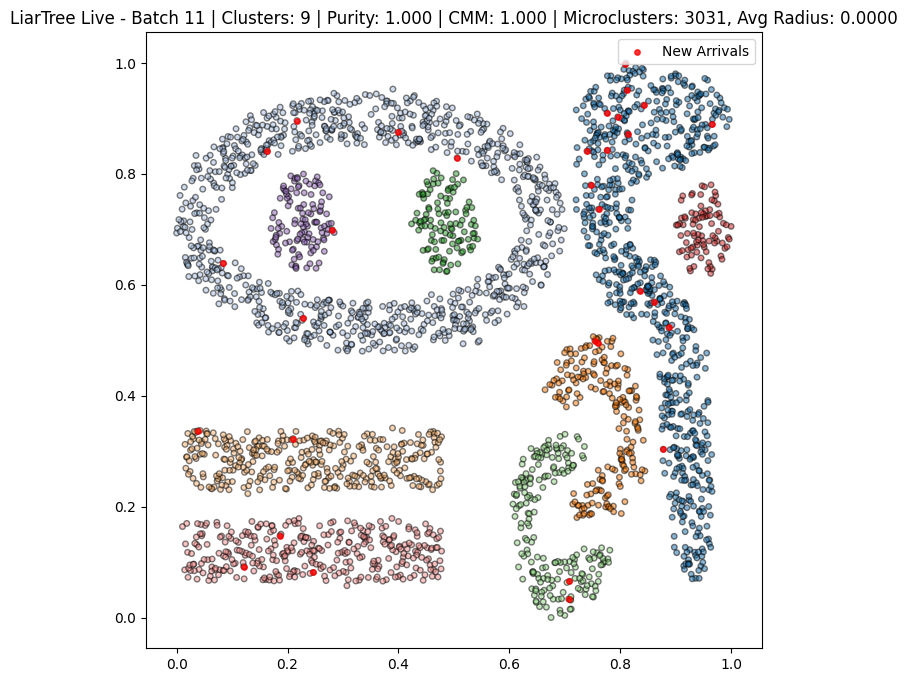

In [3]:
import sys
sys.path.insert(0, '.')
sys.path.insert(0, 'baseframework/metrics')

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from IPython.display import clear_output
from collections import Counter
import time
from baseframework import datahandler
from src.liartree import LiarTree
from src.offline import OfflineClusterer
from cmm import get_cmm

# ── Config ───────────────────────────────────────────────────────────────────────────────
DATASET_LT          = "complex9"     # choose a dataset to run LiarTree on
MAX_FANOUT_LT       = 3            # fixed
LEAF_MAX_LT         = 3          # fixed (leaf_capacity_max)
DESCENT_LT          = "depthfirst"
BUDGET_LT           = 10**9        # fixed, practically unlimited distance-computation budget
MAX_HEIGHT_LT       = 0          # unbounded
LAM_LT              = 0.001937
HORIZON_LT          = 70000
NOISE_THRESHOLD_LT  = 2.000001
OVERLAP_REDUCTION_LT = True
OFFLINE_METHOD_LT   = "dbscan"
EPS_LT              = 0.025
MIN_SAMPLES_LT      = 3
SEED_LT             = 0
BATCH_SIZE_LT       = 300
SLEEP_SEC_LT        = 1
CMM_K_LT            = 5
# ──────────────────────────────────────────────────────────────────────────────────

def compute_purity(y_true, y_pred):
    """Weighted-majority-label purity of a clustering against ground truth."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    if len(y_true) == 0:
        return 0.0
    correct = 0
    for label in set(y_pred.tolist()):
        if label == -1:
            continue
        mask = y_pred == label
        if not mask.any():
            continue
        correct += Counter(y_true[mask].tolist()).most_common(1)[0][1]
    return correct / len(y_true)


_DISTINCT_COLORS = plt.cm.tab20(np.linspace(0, 1, 20))


def get_distinct_color(cluster_id):
    return _DISTINCT_COLORS[cluster_id % len(_DISTINCT_COLORS)]


# 1. Load Data: (stream_densired, complex9, rbf3, har)
X, y_true = datahandler.load_data(DATASET_LT)

# 2. Initialize LiarTree
# - max_fanout / leaf_capacity_max: tree branching factor (fixed)
# - descent:            depth-first insertion strategy (fixed)
# - budget:              distance-computation budget per point (fixed, unlimited)
# - max_height:          cap on tree height (0 = unbounded)
# - lam:                 fading parameter lambda
# - horizon:             snapshot interval for the discard rule
# - noise_threshold:     noise probability threshold theta (Def. 2)
# - overlap_reduction:   local overlap look-ahead (Sec. 2.2)
tree = LiarTree(
    max_fanout=MAX_FANOUT_LT,
    leaf_capacity_max=LEAF_MAX_LT,
    descent=DESCENT_LT,
    budget=BUDGET_LT,
    max_height=MAX_HEIGHT_LT,
    lam=LAM_LT,
    horizon=HORIZON_LT,
    noise_threshold=NOISE_THRESHOLD_LT,
    overlap_reduction=OVERLAP_REDUCTION_LT,
)

# 3. Initialize offline phase (DBSCAN over the leaf micro-cluster summaries).
# weighted=False: LiarTree's decayed CF weights (~n * 2^-lam*age) are all << 1
# at these lam/horizon scales, so weighting would starve DBSCAN's min_samples
# check regardless of eps; unweighted counts summaries the normal DBSCAN way.
offline = OfflineClusterer(
    method=OFFLINE_METHOD_LT,
    eps=EPS_LT,
    min_samples=MIN_SAMPLES_LT,
    weighted=False,
    random_state=SEED_LT,
)

num_batches = len(X)

# Metric history for the over-time plot
lt_history_cmm = []
lt_history_purity = []
lt_history_clusters = []
lt_history_batches = []


def assign_batch_labels_lt(batch, summaries, labels_by_id):
    if len(summaries) == 0:
        return np.full(len(batch), -1)
    mc_ids = list(summaries.keys())
    centers = np.array([summaries[mid]["position"] for mid in mc_ids])
    diffs = batch[:, np.newaxis, :] - centers[np.newaxis, :, :]
    dists = np.sqrt(np.sum(diffs ** 2, axis=2))
    nearest_idx = np.argmin(dists, axis=1)
    return np.array([labels_by_id.get(mc_ids[idx], -1) for idx in nearest_idx])


# 4. Simulate streaming
for i in range(num_batches + 1):
    start_idx = i * BATCH_SIZE_LT
    end_idx = min((i + 1) * BATCH_SIZE_LT, len(X))
    batch = X[start_idx:end_idx]
    y_batch = y_true[start_idx:end_idx]

    if len(batch) == 0:
        break

    # ONLINE PHASE
    timestamps = np.arange(start_idx, end_idx) + 1
    tree.learn(batch, timestamps)

    # OFFLINE PHASE
    summaries = tree.get_summary()
    labels_by_id = offline.predict_summaries(summaries)

    # Assign each batch point to its nearest micro-cluster's label
    batch_labels = assign_batch_labels_lt(batch, summaries, labels_by_id)

    # --- Metrics (computed on current batch) ---
    unique_clusters = set(v for v in labels_by_id.values() if v != -1)
    num_clusters = len(unique_clusters)
    purity = compute_purity(y_batch, batch_labels)

    # CMM requires >= 2 predicted clusters to be meaningful
    valid_mask = batch_labels != -1
    if len(set(batch_labels[valid_mask])) >= 2 and valid_mask.sum() >= 10:
        try:
            cmm_val = get_cmm(batch, y_batch, batch_labels, np.ones(len(batch)), CMM_K_LT)
        except Exception:
            cmm_val = float('nan')
    else:
        cmm_val = float('nan')

    lt_history_cmm.append(cmm_val)
    lt_history_purity.append(purity)
    lt_history_clusters.append(num_clusters)
    lt_history_batches.append(i + 1)


    # VISUALIZATION
    clear_output(wait=True)
    fig, ax = plt.subplots(figsize=(10, 8))

    ax.scatter(X[:, 0], X[:, 1], c='whitesmoke', s=10, zorder=0)
    ax.scatter(batch[:, 0], batch[:, 1], c='red', s=15, alpha=0.8, label="New Arrivals", zorder=2)

    for mc_id, mc in summaries.items():
        center = mc["position"]
        radius = mc["radius"]
        cluster_id = labels_by_id.get(mc_id, -1)

        if cluster_id == -1:
            color = 'black'
            alpha = 0.1
            edge_style = '--'
        else:
            color = get_distinct_color(cluster_id)
            alpha = 0.5
            edge_style = '-'

        circle = Circle(center, max(radius, 0.005),
                        linewidth=1, edgecolor='black', linestyle=edge_style,
                        facecolor=color, alpha=alpha, zorder=1)
        ax.add_patch(circle)

    num_microclusters = len(summaries)
    avg_radius = tree.avg_leaf_radius()
    cmm_str = f"{cmm_val:.3f}" if not np.isnan(cmm_val) else "N/A"

    ax.set_title(
        f"LiarTree Live - Batch {i+1} | Clusters: {num_clusters} | "
        f"Purity: {purity:.3f} | CMM: {cmm_str} | "
        f"Microclusters: {num_microclusters}, Avg Radius: {avg_radius:.4f}"
    )
    ax.set_aspect('equal', 'box')
    ax.legend(loc="upper right")
    plt.show()
    time.sleep(SLEEP_SEC_LT)


## LiarTree Metrics Over Time

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].plot(lt_history_batches, lt_history_cmm, color='steelblue', marker='o', markersize=3, linewidth=1.5)
axes[0].set_ylabel("CMM")
axes[0].set_title("LiarTree Clustering Quality Metrics Over Time")
axes[0].set_ylim(0, 1)
axes[0].grid(True, alpha=0.3)

axes[1].plot(lt_history_batches, lt_history_purity, color='seagreen', marker='o', markersize=3, linewidth=1.5)
axes[1].set_ylabel("Purity")
axes[1].set_ylim(0, 1)
axes[1].grid(True, alpha=0.3)

axes[2].plot(lt_history_batches, lt_history_clusters, color='darkorange', marker='o', markersize=3, linewidth=1.5)
axes[2].set_ylabel("Cluster Count")
axes[2].set_xlabel("Batch Step")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()